In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/README.roboflow.txt
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/data.yaml
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/100_jpg.rf.677e50f854729e860e02c0471fc67783.jpg
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/100_jpg.rf.c41c2e9931775d235af0407ffcbec043.jpg
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/100_jpg.rf.d212f4c364a9d9980eee8b751f559a61.jpg
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/101_jpg.rf.73f6bd6e88c86e891edbbcef3402254a.jpg
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/101_jpg.rf.ebed18af5362f5e41251d7c5d5bccbab.jpg
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/101_jpg.rf.f9d58bc19bcb170e962e1f9e8c4e665e.jpg
/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/train/images/102_jpg.rf.4135c34838538feae6fda9

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 49.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weigths & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model = YOLO('yolo11n.pt')

In [5]:
results = model.train(
    data = '/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/data.yaml', # 数据集配置文件路径
    epochs = 30, # 训练轮数
    imgsz = 640, # 输入图片大小
    batch = 64, # 批处理大小
    val = False # 在训练过程中不进行验证
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nm


image 1/1 /kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/valid/images/553_jpg.rf.a5586080c55d3f70e84a9f6e4264acc8.jpg: 640x640 2 potholes, 10.8ms
Speed: 0.9ms preprocess, 10.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/valid/images/596_jpg.rf.d935a38d5bf91568757605ad470fd3ce.jpg: 640x640 1 pothole, 11.1ms
Speed: 0.9ms preprocess, 11.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/valid/images/13_jpg.rf.34885bb42e4ba1f9116aa9e124c95f82.jpg: 640x640 3 potholes, 10.8ms
Speed: 0.8ms preprocess, 10.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/valid/images/8_jpg.rf.88508100d861f1957cb2b3b231ac9ef1.jpg: 640x640 1 pothole, 11.0ms
Speed: 0.8ms preprocess, 11.0ms inference, 1.3ms postprocess per i

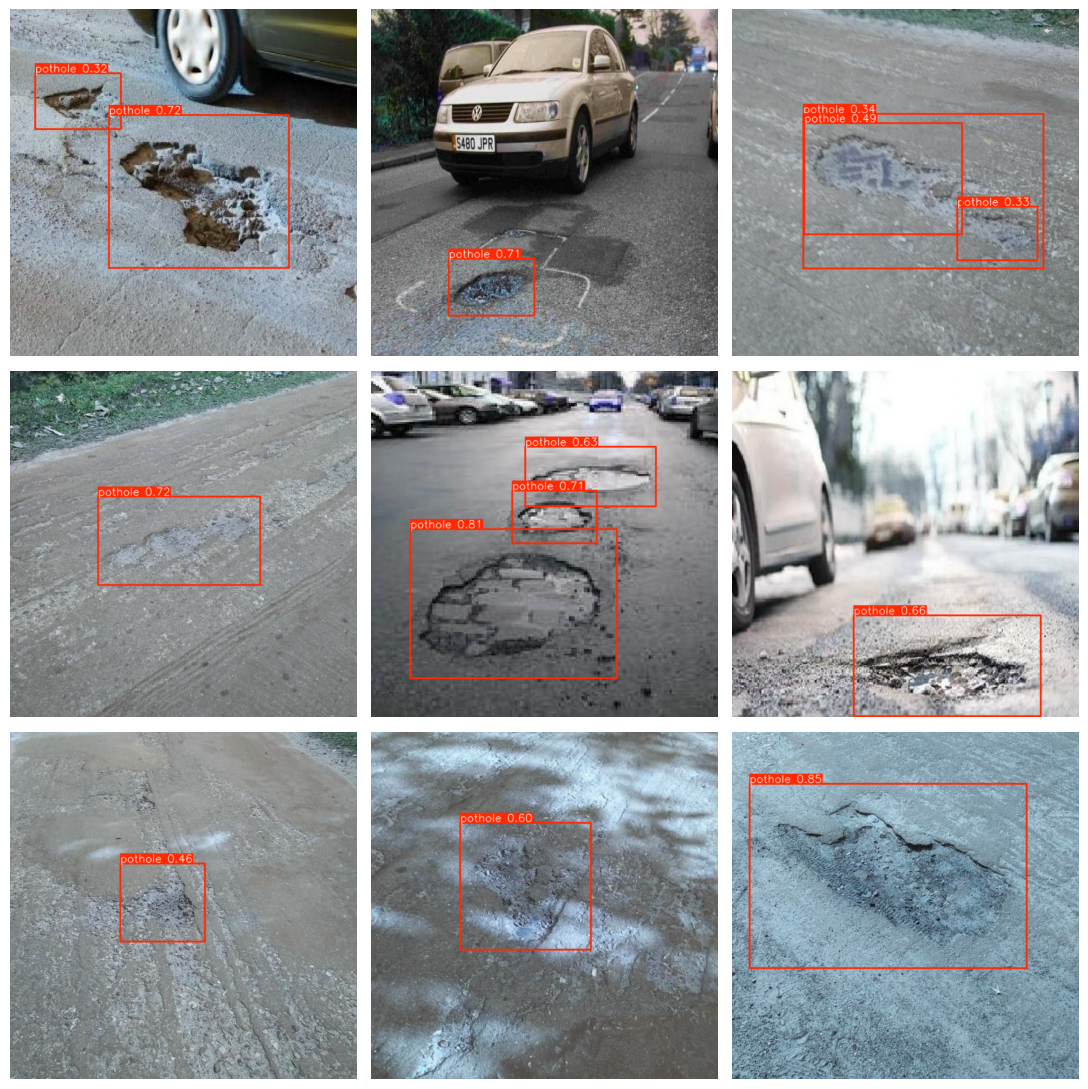

In [7]:
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
# 定义采样数量
num_samples = 9
val_img_dir = '/kaggle/input/datasets/rajdalsaniya/pothole-detection-dataset/valid/images'
# 获取测试图片目录下的所有图片文件名
image_files = os.listdir(val_img_dir)

# 随机选择指定数量的图片文件作为测试图片
val_imgs = random.sample(image_files, num_samples)

# 创建一个 3 * 3 的图幅，用于展示 9 个测试图片的预测结果
fig, axes = plt.subplots(3, 3, figsize = (11, 11))

# 遍历每个测试图片
for i in range(num_samples):
    # 获取当前测试图片的文件名
    image = val_imgs[i]
    # 根据索引确定图片在 3 * 3 图幅中的位置
    ax = axes[i // 3, i % 3]
    # 使用模型对当前测试图片进行预测
    result_predict = model.predict(source = os.path.join(val_img_dir, image))
    # 在图幅中的相应位置上展示预测结果图片
    ax.imshow(result_predict[0].plot())
    # 关闭图像坐标轴显示
    ax.axis('off')

# 调整图幅布局，确保图片标题和图片本身不重叠
plt.tight_layout()

# 展示所有测试图片的预测结果
plt.show()

In [8]:
!zip -q -r results.zip /kaggle/working/*